# Portugal Public Procurement (BASE) — Exploratory & Data Quality Analysis

This notebook explores the parquet extract produced by this repo's ingestion pipeline
(`data/contracts.parquet`, `data/entities_adjudicantes.parquet`,
`data/entities_adjudicatarios.parquet`). It works directly against the parquet files, not the
Postgres database, and replicates the parsing rules documented in
[`SCHEMA.md`](../SCHEMA.md) (NIPC/name splitting, dedup rules, derived columns) using polars.

**Sections**

1. Intro & data ingestion example
2. Column selection & rationale
3. Data quality overview
4. Adjudicantes (contracting entities) analysis, incl. fuzzy near-duplicate detection
5. Time-series analysis + a worked contract lifecycle example
6. Database/schema improvement suggestions
7. Other suggestions / limitations


In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from rapidfuzz import fuzz

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)


## 1. Intro & data ingestion example

The raw layer `data/raw/contracts_raw_<year>.parquet` is the bulk BASE export as ingested by
`bin/ingest-contracts.sh` from `data/source/contratosYYYY.xlsx`; here the years are concatenated
to one row per `idcontrato`. It is deduplicated with `keep="last"`
(BASE amends rows after signature, so the latest version wins — see `SCHEMA.md`).

Below is the raw dataframe exactly as ingested: 38 columns, the portal's own header names,
no renaming or type coercion beyond what polars infers from the xlsx/parquet round-trip.


In [2]:
# Raw per-year parquets keep the portal's own header names; the latest year wins per idcontrato.
contracts_raw = pl.concat(
    [pl.read_parquet(f) for f in sorted((DATA / "raw").glob("contracts_raw_*.parquet"))],
    how="diagonal",
).unique(subset="idcontrato", keep="last", maintain_order=True)
print(f"rows={contracts_raw.height:,}  cols={contracts_raw.width}")
contracts_raw.head()


rows=643,548  cols=39


idcontrato,nAnuncio,TipoAnuncio,idINCM,tipoContrato,idprocedimento,tipoprocedimento,objectoContrato,descContrato,adjudicante,adjudicatarios,dataPublicacao,dataCelebracaoContrato,precoContratual,CPV,prazoExecucao,LocalExecucao,fundamentacao,ProcedimentoCentralizado,numAcordoQuadro,DescrAcordoQuadro,precoBaseProcedimento,dataDecisaoAdjudicacao,dataFechoContrato,PrecoTotalEfetivo,regime,justifNReducEscrContrato,tipoFimContrato,CritMateriais,concorrentes,linkPecasProc,Observacoes,ContratEcologico,fundamentAjusteDireto,Ano,adjudicatarioPMEs,NUTs,Lotes,TipoCriterioAdjudicacao
i64,str,str,i64,str,i64,str,str,str,str,str,date,date,f64,str,i64,str,str,str,i64,str,f64,date,date,f64,str,str,str,str,str,str,str,str,str,i64,str,str,str,str
10424492,"""""",null,null,"""Aquisição de bens móveis""",6826319,"""Consulta Prévia""","""CP0424_Bufete""","""CP0424_Bufete""","""600075761 - Agrupamento de Esc…","""500917477 - Casa do Frio - Dis…",2024-01-02,2024-01-02,10116.84,"""15000000-8 - Produtos alimenta…",366,"""Portugal, Leiria, Marinha Gran…","""Artigo 20.º, n.º 1, alínea c) …","""Não""",null,null,71417.05,2023-12-22,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""501231340-Ruivo e Roda, Lda 50…",null,null,"""Não""",null,2024,null,null,"""Leite, ovos e atum""","""Monofator"""
10424554,"""""",null,null,"""Aquisição de serviços""",6845852,"""Consulta Prévia""","""Serviços de limpeza e manutenç…","""CPS20231120A - Serviços de lim…","""507809980 - Freguesia de Santa…","""- - António José Pinto""",2024-01-02,2024-01-02,9840.0,"""90600000-3 - Serviços de sanea…",364,"""Portugal, Porto, Baião""","""Artigo 20.º, n.º 1, alínea c) …","""Não""",null,null,9840.0,2023-12-22,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""--António José Pinto --Bárbara…",null,null,"""Não""",null,2024,null,null,null,"""Monofator"""
10424606,"""""",null,null,"""Aquisição de serviços""",6845893,"""Ajuste Direto Regime Geral""","""1. O presente procedimento tem…","""Ajuste Direto para Aquisição d…","""502091835 - Associação In Loco…","""502957654 - Polo Sul Informáti…",2024-01-02,2024-01-01,6300.0,"""72600000-6 - Serviços de consu…",1096,"""Portugal, Faro, São Brás de Al…","""Artigo 20.º, n.º 1, alínea d) …","""Não""",null,null,6500.0,2023-12-11,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""",null,null,null,"""Não""",null,2024,null,null,null,"""Monofator"""
10424643,"""""",null,null,"""Aquisição de serviços""",6845972,"""Ajuste Direto Regime Geral""","""1. O seguro de acidentes de tr…","""Ajuste Direto para Aquisição d…","""502091835 - Associação In Loco…","""501689168 - LUSITANIA-COMPANHI…",2024-01-02,2024-01-01,7991.1,"""66510000-8 - Serviços de segur…",1096,"""Portugal, Faro, São Brás de Al…","""Artigo 20.º, n.º 1, alínea d) …","""Não""",null,null,9000.0,2023-12-18,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""",null,null,null,"""Não""",null,2024,null,null,null,"""Monofator"""
9991791,"""671/2022""","""Aviso de prorrogação de prazo""",415197467,"""Aquisição de bens móveis""",5842544,"""Concurso público""","""Acordo Quadro para Aquisição d…","""Acordo Quadro para Aquisição d…","""512012032 - EDA - Electricidad…","""512046468 - GLOBALEDA -Telecom…",2023-05-16,2024-02-08,0.0,"""30230000-0 - Equipamento infor…",730,"""Portugal, Região Autónoma dos …","""Artigo 33.º, n.º 1 do Código d…","""Sim""",null,null,0.0,2022-08-12,null,0.0,"""Código dos Contratos Públicos …",null,null,"""Não""","""504099388-PAMAFE - Informatica…","""https://gov.saphety.com/bizgov…",null,"""Não""",null,2024,"""504099388 512046468""",null,null,"""Monofator"""


In [3]:
contracts_raw.schema


Schema([('idcontrato', Int64),
        ('nAnuncio', String),
        ('TipoAnuncio', String),
        ('idINCM', Int64),
        ('tipoContrato', String),
        ('idprocedimento', Int64),
        ('tipoprocedimento', String),
        ('objectoContrato', String),
        ('descContrato', String),
        ('adjudicante', String),
        ('adjudicatarios', String),
        ('dataPublicacao', Date),
        ('dataCelebracaoContrato', Date),
        ('precoContratual', Float64),
        ('CPV', String),
        ('prazoExecucao', Int64),
        ('LocalExecucao', String),
        ('fundamentacao', String),
        ('ProcedimentoCentralizado', String),
        ('numAcordoQuadro', Int64),
        ('DescrAcordoQuadro', String),
        ('precoBaseProcedimento', Float64),
        ('dataDecisaoAdjudicacao', Date),
        ('dataFechoContrato', Date),
        ('PrecoTotalEfetivo', Float64),
        ('regime', String),
        ('justifNReducEscrContrato', String),
        ('tipoFimContrato', Str

In [4]:
entities_adjudicantes_raw = pl.read_parquet(DATA / "entities_adjudicantes.parquet")
entities_adjudicatarios_raw = pl.read_parquet(DATA / "entities_adjudicatarios.parquet")
print("adjudicantes:", entities_adjudicantes_raw.shape, entities_adjudicantes_raw.columns)
print("adjudicatarios:", entities_adjudicatarios_raw.shape, entities_adjudicatarios_raw.columns)
entities_adjudicantes_raw.head()


adjudicantes: (6847, 2) ['entity_id', 'name']
adjudicatarios: (89950, 2) ['entity_id', 'name']


entity_id,name
str,str
"""500940037""","""Fundação Gaspar e Manuel Cardo…"
"""505987236""","""Horas de Sonho - Apoio à Crian…"
"""504079700""","""Santa Casa da Misericórdia de …"
"""512042705""","""ARDE - Associação Regional Par…"
"""513033424""","""Qualifica-te RHL, Lda."""


## 2. Column selection & rationale

The raw export carries 38 columns, several of which are free-text, near-empty, or redundant
with derived fields. We first check null rates for every column to justify what to keep vs
drop, then build the analysis-ready dataframe that mirrors the `contracts` table in
`SCHEMA.md` (with `adjudicante_nipc` / `adjudicante_name` split out of the packed
`"NIPC name"` string, as documented).


In [5]:
null_rates = (
    contracts_raw
    .null_count()
    .transpose(include_header=True, header_name="column", column_names=["nulls"])
    .with_columns((pl.col("nulls") / contracts_raw.height * 100).round(1).alias("null_pct"))
    .sort("null_pct", descending=True)
)
null_rates


column,nulls,null_pct
str,u32,f64
"""Observacoes""",618287,96.1
"""fundamentAjusteDireto""",604350,93.9
"""numAcordoQuadro""",544039,84.5
"""DescrAcordoQuadro""",544039,84.5
"""TipoAnuncio""",542807,84.3
"""idINCM""",542807,84.3
"""tipoFimContrato""",530605,82.4
"""dataFechoContrato""",528625,82.1
"""Lotes""",494533,76.8


### Columns kept (and why)

| Column (raw → final) | Why it's useful |
| --- | --- |
| `idcontrato` → `idcontrato` | Primary key, needed to dedup/join and as the grain of every aggregation. |
| `adjudicante` → `adjudicante_nipc`, `adjudicante_name` | Split into a stable join key (NIPC) plus a display name; core to the entity analysis in §4. |
| `adjudicatarios` → `adjudicatarios` (kept packed) plus parsed `adjudicatarios_nipc`, `adjudicatarios_name` (`\n`-joined strings, one entry per awardee), `adjudicatarios_nipc_correct` (NIPC check) and `number_adjudicatarios` | Needed to look at awardees. Each `"NIPC - name"` entry is split, NIPCs are checked for 9 digits (`YES`, `NO_NIF`, `WRONG_LENGTH`, `NIF_INCORRECTLY_PARSED`). A full bridge table (one row per awardee, as in `contract_adjudicatarios`) is still deferred to keep this notebook focused on the fact table. |
| `concorrentes` → `concorrentes` (packed, plus parsed `concorrentes_nipc` / `concorrentes_name` as `\n`-joined strings and `concorrentes_nipc_correct`) | Competing bidders (`NIPC-name`, one per line), parsed the same way as `adjudicatarios`. |
| `objectoContrato` → `objecto_contrato` | Short free-text description of what was procured — used for the worked contract example in §5 and for eyeballing outliers. |
| `precoContratual` → `preco_contratual` | The contracted price — the main value metric, ~0% null. |
| `PrecoTotalEfetivo` → `preco_total_efetivo` | The *effective* price once the contract closes — nullable until closure; central to the lifecycle example in §5. |
| `dataPublicacao` → `data_publicacao` | Publication date — anchors the time series and the lifecycle example. |
| `dataCelebracaoContrato` → `data_celebracao` | Contract signature date — the primary date used for time-series binning (matches `SCHEMA.md`, which indexes this column). |
| `dataFechoContrato` → `data_fecho` | Closure date, nullable — used for the lifecycle example and to gauge how many contracts are still open. |
| `CPV` → `cpv` | Product/service classification — indexed in Postgres, useful for category cuts (not deeply explored here, flagged for §7). |
| `NUTs` → `nuts` | Geography — flagged for §7 (worth a hierarchy table). |
| `Ano` → `ano` | Contract year, redundant with `data_celebracao` but cheap and exactly matches the Postgres `ano` column/index; kept for direct year filters. |
| `tipoContrato` → `tipo_contrato` | Contract type — low cardinality, useful segmentation dimension. |
| `tipoprocedimento` → `tipo_procedimento` | Procurement procedure type (e.g. ajuste direto vs concurso público) — a common Grafana filter. |
| `adjudicatarioPMEs` → `adjudicatario_pmes` | SME flag — cheap, useful for a policy-relevant cut. |
| `prazoExecucao` → `prazo_execucao` | Execution deadline in days — useful for duration analysis. |

### Columns dropped (and why)

- `nAnuncio`, `TipoAnuncio`, `idINCM` — almost entirely null (see table above) or purely an
  internal announcement identifier with no analytical value.
- `idprocedimento`, `numAcordoQuadro`, `DescrAcordoQuadro`, `ProcedimentoCentralizado` — mostly
  null / niche procedural metadata not needed for a first analytical pass.
- `descContrato` — long free-text duplicate of `objectoContrato`, adds size without new signal
  for aggregate analysis.
- `precoBaseProcedimento`, `dataDecisaoAdjudicacao` — largely null and redundant with
  `precoContratual` / `dataCelebracaoContrato` for our purposes.
- `regime`, `justifNReducEscrContrato`, `tipoFimContrato`, `CritMateriais`,
  `linkPecasProc`, `Observacoes`, `ContratEcologico`, `fundamentAjusteDireto`, `fundamentacao`,
  `LocalExecucao`, `Lotes`, `TipoCriterioAdjudicacao` — free-text / high-null / niche legal
  fields not needed for the quantitative analysis in this notebook; they remain available in
  the raw parquet if a future pass needs them.

This mirrors — and is a subset of — the `contracts` table columns in `SCHEMA.md`; the DB load
keeps a couple more fields than this notebook does for brevity.


In [6]:
def split_packed(col: str, nipc_alias: str, name_alias: str) -> list[pl.Expr]:
    """Split a packed 'NIPC - name' string into two columns, mirroring xlsx_ingest.py."""
    parts = pl.col(col).str.strip_chars().str.splitn(" ", 2)
    return [
        parts.struct.field("field_0").alias(nipc_alias),
        # drop the "- " separator left over after splitting on the first space
        parts.struct.field("field_1").str.strip_prefix("- ").alias(name_alias),
    ]

contracts = (
    contracts_raw
    .with_columns(split_packed("adjudicante", "adjudicante_nipc", "adjudicante_name"))
    .select(
        pl.col("idcontrato"),
        pl.col("adjudicante_nipc"),
        pl.col("adjudicante_name"),
        pl.col("adjudicatarios"),
        pl.col("concorrentes"),
        pl.col("objectoContrato").alias("objecto_contrato"),
        pl.col("precoContratual").alias("preco_contratual"),
        pl.col("PrecoTotalEfetivo").alias("preco_total_efetivo"),
        pl.col("dataPublicacao").alias("data_publicacao"),
        pl.col("dataCelebracaoContrato").alias("data_celebracao"),
        pl.col("dataFechoContrato").alias("data_fecho"),
        pl.col("CPV").alias("cpv"),
        pl.col("NUTs").alias("nuts"),
        pl.col("Ano").alias("ano"),
        pl.col("tipoContrato").alias("tipo_contrato"),
        pl.col("tipoprocedimento").alias("tipo_procedimento"),
        pl.col("adjudicatarioPMEs").alias("adjudicatario_pmes"),
        pl.col("prazoExecucao").alias("prazo_execucao"),
    )
)
contracts.head()


idcontrato,adjudicante_nipc,adjudicante_name,adjudicatarios,concorrentes,objecto_contrato,preco_contratual,preco_total_efetivo,data_publicacao,data_celebracao,data_fecho,cpv,nuts,ano,tipo_contrato,tipo_procedimento,adjudicatario_pmes,prazo_execucao
i64,str,str,str,str,str,f64,f64,date,date,date,str,str,i64,str,str,str,i64
10424492,"""600075761""","""Agrupamento de Escolas Marinha…","""500917477 - Casa do Frio - Dis…","""501231340-Ruivo e Roda, Lda 50…","""CP0424_Bufete""",10116.84,0.0,2024-01-02,2024-01-02,null,"""15000000-8 - Produtos alimenta…",null,2024,"""Aquisição de bens móveis""","""Consulta Prévia""",null,366
10424554,"""507809980""","""Freguesia de Santa Marinha do …","""- - António José Pinto""","""--António José Pinto --Bárbara…","""Serviços de limpeza e manutenç…",9840.0,0.0,2024-01-02,2024-01-02,null,"""90600000-3 - Serviços de sanea…",null,2024,"""Aquisição de serviços""","""Consulta Prévia""",null,364
10424606,"""502091835""","""Associação In Loco de Interven…","""502957654 - Polo Sul Informáti…",null,"""1. O presente procedimento tem…",6300.0,0.0,2024-01-02,2024-01-01,null,"""72600000-6 - Serviços de consu…",null,2024,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,1096
10424643,"""502091835""","""Associação In Loco de Interven…","""501689168 - LUSITANIA-COMPANHI…",null,"""1. O seguro de acidentes de tr…",7991.1,0.0,2024-01-02,2024-01-01,null,"""66510000-8 - Serviços de segur…",null,2024,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,1096
9991791,"""512012032""","""EDA - Electricidade dos Açores…","""512046468 - GLOBALEDA -Telecom…","""504099388-PAMAFE - Informatica…","""Acordo Quadro para Aquisição d…",0.0,0.0,2023-05-16,2024-02-08,null,"""30230000-0 - Equipamento infor…",null,2024,"""Aquisição de bens móveis""","""Concurso público""","""504099388 512046468""",730


In [7]:
# Parse packed "NIPC <sep> name" columns (one entry per line) into list columns plus a NIPC check.
# Every row gets lists (length 1 for single-entry rows) so the column has one dtype.
# Row-level `<prefix>_nipc_correct` takes the worst status among the row's entries:
# NIF_INCORRECTLY_PARSED > WRONG_LENGTH > NO_NIF > YES.
def parse_entities(df: pl.DataFrame, col: str, prefix: str, split_entry) -> pl.DataFrame:
    """`split_entry(entry_expr) -> (raw_nipc_expr, name_expr)`; name is null when unsplittable."""
    entries = (
        df.filter(pl.col(col).is_not_null())
        .select("idcontrato", pl.col(col).str.split("\n").alias("entry"))
        .explode("entry")
        .with_columns(pl.col("entry").str.strip_chars())
        .with_columns(
            split_entry(pl.col("entry"))[0].alias("raw_nipc"),
            split_entry(pl.col("entry"))[1].alias("name"),
        )
        # NIPC may be padded/split by whitespace (spaces, tabs) or a literal "\t" typed as text,
        # e.g. "502 544 180" or "502496878\\t"
        .with_columns(pl.col("raw_nipc").str.replace_all(r"(?:\s|\\t)+", "").alias("clean_nipc"))
        .with_columns(
            pl.when(pl.col("name").is_null())
            .then(pl.lit("NIF_INCORRECTLY_PARSED"))
            .when(pl.col("raw_nipc") == "-")  # entry without a NIF
            .then(pl.lit("NO_NIF"))
            .when(pl.col("clean_nipc").str.contains(r"^\d{9}$"))
            .then(pl.lit("YES"))
            .when(pl.col("clean_nipc").str.contains(r"^\d+$"))
            .then(pl.lit("WRONG_LENGTH"))
            .otherwise(pl.lit("NIF_INCORRECTLY_PARSED"))
            .alias("status"),
            pl.when(pl.col("clean_nipc").str.contains(r"^\d+$"))
            .then(pl.col("clean_nipc"))
            .otherwise(pl.col("raw_nipc"))
            .alias("nipc"),
        )
    )
    per_contract = entries.group_by("idcontrato", maintain_order=True).agg(
        pl.col("nipc").alias(f"{prefix}_nipc"),
        pl.col("name").alias(f"{prefix}_name"),
        pl.when((pl.col("status") == "NIF_INCORRECTLY_PARSED").any())
        .then(pl.lit("NIF_INCORRECTLY_PARSED"))
        .when((pl.col("status") == "WRONG_LENGTH").any())
        .then(pl.lit("WRONG_LENGTH"))
        .when((pl.col("status") == "NO_NIF").any())
        .then(pl.lit("NO_NIF"))
        .otherwise(pl.lit("YES"))
        .alias(f"{prefix}_nipc_correct"),
    )
    return df.join(per_contract, on="idcontrato", how="left")


def split_adjudicatario(entry: pl.Expr) -> tuple[pl.Expr, pl.Expr]:
    """'NIPC - name'; awardees without NIF come as '- - name'."""
    parts = entry.str.splitn(" - ", 2)
    return parts.struct.field("field_0"), parts.struct.field("field_1")


contracts = parse_entities(contracts, "adjudicatarios", "adjudicatarios", split_adjudicatario).with_columns(
    (pl.col("adjudicatarios").str.count_matches("\n", literal=True) + 1).alias("number_adjudicatarios")
).with_columns(
    # NIPCs and names as single strings, one per line (same layout as the raw column)
    pl.col("adjudicatarios_nipc", "adjudicatarios_name").list.join("\n")
)

print("adjudicatarios_nipc_correct:")
display(contracts["adjudicatarios_nipc_correct"].value_counts(sort=True))

print("Contracts with several adjudicatarios, by number_adjudicatarios:")
display(contracts["number_adjudicatarios"].value_counts().sort("number_adjudicatarios").head(10))

print("Cases mentioned by hand (11541529: wrong length, 11385814: NIPC split by spaces):")
with pl.Config(fmt_str_lengths=120, tbl_rows=-1, tbl_width_chars=250):
    display(
        contracts.filter(pl.col("idcontrato").is_in([11541529, 11385814])).select(
            "idcontrato",
            "number_adjudicatarios",
            "adjudicatarios_nipc",
            "adjudicatarios_name",
            "adjudicatarios_nipc_correct",
        )
    )

not_parsed = contracts.filter(pl.col("adjudicatarios_nipc_correct") == "NIF_INCORRECTLY_PARSED")
print(f"NIF_INCORRECTLY_PARSED: {not_parsed.height} contracts")
with pl.Config(fmt_str_lengths=300, tbl_rows=-1, tbl_width_chars=250):
    display(not_parsed.select("idcontrato", "adjudicatarios"))


/var/folders/qm/v8q4c7z96x3___vhx5_pxyc00000gn/T/ipykernel_99861/3627901647.py:10: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .explode("entry")


adjudicatarios_nipc_correct:


adjudicatarios_nipc_correct,count
str,u32
"""YES""",574884
"""NO_NIF""",68472
null,189
"""WRONG_LENGTH""",2
"""NIF_INCORRECTLY_PARSED""",1


Contracts with several adjudicatarios, by number_adjudicatarios:


number_adjudicatarios,count
u32,u32
null,189
1,640570
2,1288
3,452
4,245
5,155
6,101
7,87
8,63


Cases mentioned by hand (11541529: wrong length, 11385814: NIPC split by spaces):


idcontrato,number_adjudicatarios,adjudicatarios_nipc,adjudicatarios_name,adjudicatarios_nipc_correct
i64,u32,str,str,str
11385814,1,"""502544180""","""Vodafone Portugal – Comunicações Pessoais S.A.""","""YES"""
11541529,6,"""51372670 980245974 500697370 514362650 516248197 503504564""","""Luzboa - Comercialização de Energia, Lda. Endesa Energia, S.A. - Sucursal Portugal PETROGAL, S.A. Alfa Energia Lda Power…","""WRONG_LENGTH"""


NIF_INCORRECTLY_PARSED: 1 contracts


idcontrato,adjudicatarios
i64,str
11216510,"""507857542_1 - Gold Energy - Comercializadora de Energia, S.A."""


In [8]:
# Same treatment for `concorrentes` (competing bidders). Format is "NIPC-name" (no spaces around
# the hyphen), one entry per line; bidders without NIF come as "--name".
def split_concorrente(entry: pl.Expr) -> tuple[pl.Expr, pl.Expr]:
    no_nif = entry.str.starts_with("--")
    raw_nipc = pl.when(no_nif).then(pl.lit("-")).otherwise(entry.str.extract(r"^([^-]*)-", 1))
    name = (
        pl.when(no_nif)
        .then(entry.str.slice(2))
        .otherwise(entry.str.extract(r"^[^-]*-(.*)$", 1))
        .str.strip_chars()
    )
    return raw_nipc, name


contracts = parse_entities(contracts, "concorrentes", "concorrentes", split_concorrente)
contracts = contracts.with_columns(pl.col("concorrentes_nipc", "concorrentes_name").list.join("\n"))

# Column order: parsed adjudicatarios next to the adjudicante columns; the raw/derived
# adjudicatarios and concorrentes columns go last; everything else keeps its original order.
front = [
    "idcontrato",
    "adjudicante_nipc",
    "adjudicante_name",
    "adjudicatarios_nipc",
    "adjudicatarios_name",
]
back = [
    "adjudicatarios",
    "adjudicatarios_nipc_correct",
    "number_adjudicatarios",
    "concorrentes",
    "concorrentes_nipc",
    "concorrentes_name",
    "concorrentes_nipc_correct",
]
contracts = contracts.select(*front, pl.exclude(front + back), *back)

print("concorrentes_nipc_correct:")
display(contracts["concorrentes_nipc_correct"].value_counts(sort=True))

odd = contracts.filter(
    pl.col("concorrentes_nipc_correct").is_in(["NIF_INCORRECTLY_PARSED", "WRONG_LENGTH"])
)
print(f"NIF_INCORRECTLY_PARSED / WRONG_LENGTH: {odd.height} contracts (first 50 shown)")
with pl.Config(fmt_str_lengths=300, tbl_rows=-1, tbl_width_chars=250):
    display(odd.select("idcontrato", "concorrentes", "concorrentes_nipc_correct").head(50))


/var/folders/qm/v8q4c7z96x3___vhx5_pxyc00000gn/T/ipykernel_99861/3627901647.py:10: DeprecationWarning: In Polars 2.0, the default behavior for `empty_as_null` will change to `False`. To keep the current behavior, explicitly set `empty_as_null=True`.
  .explode("entry")


concorrentes_nipc_correct:


concorrentes_nipc_correct,count
str,u32
null,368662
"""YES""",235170
"""NO_NIF""",39715
"""NIF_INCORRECTLY_PARSED""",1


NIF_INCORRECTLY_PARSED / WRONG_LENGTH: 1 contracts (first 50 shown)


idcontrato,concorrentes,concorrentes_nipc_correct
i64,str,str
10661671,"""500697370- Petrogal, S.A. 980245974-ENDESA ENERGIA SA - SUCURSAL PORTUGAL 507857542_1-Gold Energy - Comercializadora de Energia, S.A. 503504564-EDP COMERCIAL - COMERCIALIZAÇÃO DE ENERGIA, SA""","""NIF_INCORRECTLY_PARSED"""


In [9]:
contracts.head(5)

idcontrato,adjudicante_nipc,adjudicante_name,adjudicatarios_nipc,adjudicatarios_name,objecto_contrato,preco_contratual,preco_total_efetivo,data_publicacao,data_celebracao,data_fecho,cpv,nuts,ano,tipo_contrato,tipo_procedimento,adjudicatario_pmes,prazo_execucao,adjudicatarios,adjudicatarios_nipc_correct,number_adjudicatarios,concorrentes,concorrentes_nipc,concorrentes_name,concorrentes_nipc_correct
i64,str,str,str,str,str,f64,f64,date,date,date,str,str,i64,str,str,str,i64,str,str,u32,str,str,str,str
10424492,"""600075761""","""Agrupamento de Escolas Marinha…","""500917477""","""Casa do Frio - Distribuição Al…","""CP0424_Bufete""",10116.84,0.0,2024-01-02,2024-01-02,null,"""15000000-8 - Produtos alimenta…",null,2024,"""Aquisição de bens móveis""","""Consulta Prévia""",null,366,"""500917477 - Casa do Frio - Dis…","""YES""",1,"""501231340-Ruivo e Roda, Lda 50…","""501231340 501895230 514356561 …","""Ruivo e Roda, Lda Frubaça A. A…","""YES"""
10424554,"""507809980""","""Freguesia de Santa Marinha do …","""-""","""António José Pinto""","""Serviços de limpeza e manutenç…",9840.0,0.0,2024-01-02,2024-01-02,null,"""90600000-3 - Serviços de sanea…",null,2024,"""Aquisição de serviços""","""Consulta Prévia""",null,364,"""- - António José Pinto""","""NO_NIF""",1,"""--António José Pinto --Bárbara…","""- - -""","""António José Pinto Bárbara Raq…","""NO_NIF"""
10424606,"""502091835""","""Associação In Loco de Interven…","""502957654""","""Polo Sul Informática Lda""","""1. O presente procedimento tem…",6300.0,0.0,2024-01-02,2024-01-01,null,"""72600000-6 - Serviços de consu…",null,2024,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,1096,"""502957654 - Polo Sul Informáti…","""YES""",1,null,null,null,null
10424643,"""502091835""","""Associação In Loco de Interven…","""501689168""","""LUSITANIA-COMPANHIA DE SEGUROS…","""1. O seguro de acidentes de tr…",7991.1,0.0,2024-01-02,2024-01-01,null,"""66510000-8 - Serviços de segur…",null,2024,"""Aquisição de serviços""","""Ajuste Direto Regime Geral""",null,1096,"""501689168 - LUSITANIA-COMPANHI…","""YES""",1,null,null,null,null
9991791,"""512012032""","""EDA - Electricidade dos Açores…","""512046468 504099388""","""GLOBALEDA -Telecomunicações e …","""Acordo Quadro para Aquisição d…",0.0,0.0,2023-05-16,2024-02-08,null,"""30230000-0 - Equipamento infor…",null,2024,"""Aquisição de bens móveis""","""Concurso público""","""504099388 512046468""",730,"""512046468 - GLOBALEDA -Telecom…","""YES""",2,"""504099388-PAMAFE - Informatica…","""504099388 512046468""","""PAMAFE - Informatica, Lda GLOB…","""YES"""


## 3. Data quality overview

Nulls, dtypes, duplicate keys, date-range sanity, and price outliers on the cleaned dataframe.


In [10]:
(
    contracts
    .null_count()
    .transpose(include_header=True, header_name="column", column_names=["nulls"])
    .with_columns((pl.col("nulls") / contracts.height * 100).round(1).alias("null_pct"))
    .sort("null_pct", descending=True)
)


column,nulls,null_pct
str,u32,f64
"""data_fecho""",528625,82.1
"""concorrentes""",368662,57.3
"""concorrentes_nipc""",368662,57.3
"""concorrentes_name""",368662,57.3
"""concorrentes_nipc_correct""",368662,57.3
"""nuts""",340838,53.0
"""adjudicatario_pmes""",109545,17.0
"""data_celebracao""",1971,0.3
"""idcontrato""",0,0.0


In [11]:
print("dtypes:")
for name, dtype in contracts.schema.items():
    print(f"  {name:<22} {dtype}")

dup_ids = contracts.height - contracts.select("idcontrato").n_unique()
print(f"\nduplicate idcontrato rows: {dup_ids}")


dtypes:
  idcontrato             Int64
  adjudicante_nipc       String
  adjudicante_name       String
  adjudicatarios_nipc    String
  adjudicatarios_name    String
  objecto_contrato       String
  preco_contratual       Float64
  preco_total_efetivo    Float64
  data_publicacao        Date
  data_celebracao        Date
  data_fecho             Date
  cpv                    String
  nuts                   String
  ano                    Int64
  tipo_contrato          String
  tipo_procedimento      String
  adjudicatario_pmes     String
  prazo_execucao         Int64
  adjudicatarios         String
  adjudicatarios_nipc_correct String
  number_adjudicatarios  UInt32
  concorrentes           String
  concorrentes_nipc      String
  concorrentes_name      String
  concorrentes_nipc_correct String

duplicate idcontrato rows: 0


In [12]:
print("data_celebracao range:", contracts["data_celebracao"].min(), "→", contracts["data_celebracao"].max())
print("data_publicacao range:", contracts["data_publicacao"].min(), "→", contracts["data_publicacao"].max())
print("data_fecho range (non-null):", contracts["data_fecho"].min(), "→", contracts["data_fecho"].max())

# rows where celebration predates publication (should be rare/zero — a sanity check)
suspect_dates = contracts.filter(pl.col("data_celebracao") < pl.col("data_publicacao"))
print(f"\ncontracts celebrated before publication: {suspect_dates.height} ({suspect_dates.height / contracts.height:.2%})")


data_celebracao range: 2024-01-01 → 2026-09-11
data_publicacao range: 2023-05-16 → 2026-09-12
data_fecho range (non-null): 1926-02-01 → 2026-09-11

contracts celebrated before publication: 551957 (85.77%)


In [13]:
price_stats = contracts.select(
    pl.col("preco_contratual").min().alias("min"),
    pl.col("preco_contratual").max().alias("max"),
    pl.col("preco_contratual").mean().round(2).alias("mean"),
    pl.col("preco_contratual").median().alias("median"),
    (pl.col("preco_contratual") <= 0).sum().alias("zero_or_negative"),
    (pl.col("preco_contratual") < 0).sum().alias("negative"),
)
price_stats


min,max,mean,median,zero_or_negative,negative
f64,f64,f64,f64,u32,u32
-207000.0,1.6614e9,87970.87,11463.035,1396,12


In [14]:
# top-10 most expensive contracts — a quick outlier sanity check
contracts.sort("preco_contratual", descending=True).select(
    "idcontrato", "adjudicante_name", "objecto_contrato", "preco_contratual", "data_celebracao"
).head(10)


idcontrato,adjudicante_name,objecto_contrato,preco_contratual,data_celebracao
i64,str,str,f64,date
11724697,"""Infraestruturas de Portugal, S…","""Concurso Público com Publicida…",1.6614e9,2025-07-29
11817114,"""CP - Comboios de Portugal EPE""",""" O objeto deste procedimento c…",7.4604e8,2025-10-14
11395086,"""Associação de Municípios para …","""Concurso Limitado por Prévia Q…",2.6714e8,2025-04-30
11314392,"""Portos dos Açores, S. A.""","""EMPREITADA DE CONSTRUÇÃO DO NO…",1.9483e8,2025-03-23
15377619,"""EDA - Electricidade dos Açores…","""Fornecimento de Fuelóleo para …",1.6833e8,2026-07-27
15277559,"""Infraestruturas de Portugal, S…","""Empreitada LINHA DO ALENTEJO M…",1.6696e8,2026-07-09
11525852,"""EEM - Empresa de Electricidade…","""Adenda ao Contrato de Compra d…",1.61e8,2025-06-11
13507613,"""Unidade Local de Saúde de Sant…","""Medicamento Vutrisiran 50 mg/m…",1.56231216e8,2026-02-04
10617290,"""Infraestruturas de Portugal""","""FORNECIMENTO, INSTALAÇÃO, MONT…",1.39e8,2024-03-13


**Observations:** null rates are low for the core value/date fields we kept (`preco_contratual`,
`data_celebracao`, `data_publicacao`, `idcontrato`) and higher for `data_fecho` /
`preco_total_efetivo` — expected, since those only populate once a contract closes.
`idcontrato` has no duplicates, confirming the `keep="last"` dedup worked at ingestion. A small
number of very high-value contracts (national infrastructure / framework agreements) dominate
the tail of the price distribution — worth flagging as a watchlist rather than removing, see §7.

The parsed `adjudicatarios_nipc_correct` / `concorrentes_nipc_correct` flags (built in §2) give a
quick NIPC quality read: most awardees carry a valid 9-digit NIPC (`YES`), roughly one in nine
contracts has at least one awardee without a NIF (`NO_NIF`; the samples we looked at are natural persons
and foreign companies), and only a handful are `WRONG_LENGTH` or `NIF_INCORRECTLY_PARSED`. `concorrentes` is
null for over half of the contracts (no competing bidders recorded), so its flag is null there
too, as is `adjudicatarios_nipc_correct` for the few contracts with no awardee at all.


## 4. Adjudicantes (contracting entities) analysis

Top entities by contract count and by total contracted value, the distribution of contracts
per entity, and a fuzzy-matching pass to surface likely near-duplicate entity names (accents,
case, abbreviations, whitespace) that may need merging beyond the NIPC-based join.


In [15]:
by_entity = (
    contracts
    .filter(pl.col("adjudicante_nipc").is_not_null())
    .group_by("adjudicante_nipc", "adjudicante_name")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
    )
)

print("Top 15 entities by contract count:")
display(by_entity.sort("n_contracts", descending=True).head(15))

print("\nTop 15 entities by total contracted value:")
display(by_entity.sort("total_value", descending=True).head(15))


Top 15 entities by contract count:


adjudicante_nipc,adjudicante_name,n_contracts,total_value
str,str,u32,f64
"""506362299""","""Instituto Português de Oncolog…",30835,2.9773e8
"""508142156""","""Unidade Local de Saúde de Gaia…",11031,3.3601e8
"""508481287""","""Unidade Local de Saúde de Sant…",10495,1.2037e9
"""506362299""","""Instituto Português de Oncolog…",8812,1.6512e8
"""508080142""","""Unidade Local de Saúde de São …",7596,7.7791e8
"""510103448""","""Unidade Local de Saúde de Coim…",6951,7.7292e8
"""502011378""","""Universidade do Minho""",5613,8.0774e7
"""513606084""","""Águas do Norte, S. A.""",5340,2.1104e8
"""508094461""","""Unidade Local de Saúde do Alto…",5095,4.3208e7



Top 15 entities by total contracted value:


adjudicante_nipc,adjudicante_name,n_contracts,total_value
str,str,u32,f64
"""503933813""","""Infraestruturas de Portugal, S…",1244,3.1211e9
"""508481287""","""Unidade Local de Saúde de Sant…",10495,1.2037e9
"""517392259""","""Unidade Local de Saúde de Sant…",3190,8.8915e8
"""508080142""","""Unidade Local de Saúde de São …",7596,7.7791e8
"""510103448""","""Unidade Local de Saúde de Coim…",6951,7.7292e8
"""500498601""","""CP - Comboios de Portugal EPE""",12,7.5054e8
"""503933813""","""Infraestruturas de Portugal, S…",440,6.8304e8
"""600010686""","""Estado Maior da Força Aérea""",4409,6.0352e8
"""505187531""","""Município de Cascais""",1354,5.5651e8


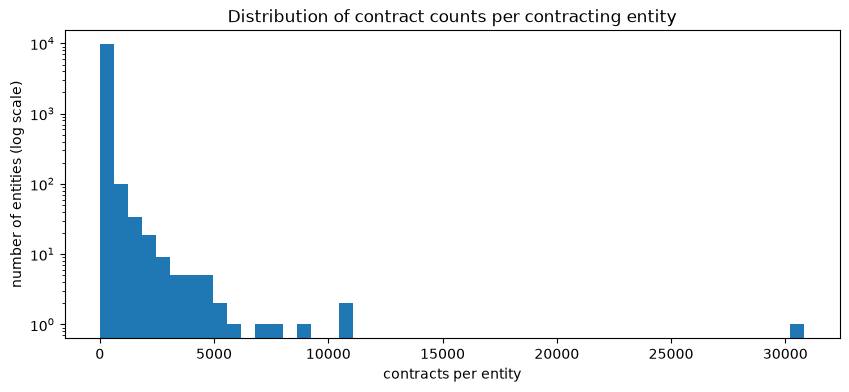

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 9824.0     │
│ null_count ┆ 0.0        │
│ mean       ┆ 65.507736  │
│ std        ┆ 453.715707 │
│ min        ┆ 1.0        │
│ 25%        ┆ 1.0        │
│ 50%        ┆ 4.0        │
│ 75%        ┆ 20.0       │
│ max        ┆ 30835.0    │
└────────────┴────────────┘


In [16]:
counts = by_entity["n_contracts"].to_numpy()
fig, ax = plt.subplots()
ax.hist(counts, bins=50, log=True)
ax.set_xlabel("contracts per entity")
ax.set_ylabel("number of entities (log scale)")
ax.set_title("Distribution of contract counts per contracting entity")
plt.show()

print(by_entity["n_contracts"].describe())


In [17]:
# Fuzzy near-duplicate name detection.
# Strategy: normalize names (lowercase, strip accents/punctuation), then for entities whose
# normalized names are similar (token_sort_ratio >= 90) but whose NIPC differs, flag as a
# merge candidate. We restrict the comparison to entities with a meaningful contract count to
# keep this tractable and to focus on cases that matter for the dashboards.
import unicodedata


def normalize(name: str) -> str:
    name = unicodedata.normalize("NFKD", name).encode("ascii", "ignore").decode()
    return " ".join(name.lower().replace(".", " ").split())

candidates = (
    by_entity.filter(pl.col("n_contracts") >= 5)
    .with_columns(pl.col("adjudicante_name").map_elements(normalize, return_dtype=pl.String).alias("norm_name"))
    .sort("n_contracts", descending=True)
    .head(400)  # cap for O(n^2) comparison cost
    .to_dicts()
)

pairs = []
for i in range(len(candidates)):
    for j in range(i + 1, len(candidates)):
        a, b = candidates[i], candidates[j]
        if a["adjudicante_nipc"] == b["adjudicante_nipc"]:
            continue
        score = fuzz.token_sort_ratio(a["norm_name"], b["norm_name"])
        if score >= 90:
            pairs.append({
                "nipc_a": a["adjudicante_nipc"], "name_a": a["adjudicante_name"],
                "nipc_b": b["adjudicante_nipc"], "name_b": b["adjudicante_name"],
                "score": score,
            })

fuzzy_df = pl.DataFrame(pairs).sort("score", descending=True) if pairs else pl.DataFrame(
    schema={"nipc_a": pl.String, "name_a": pl.String, "nipc_b": pl.String, "name_b": pl.String, "score": pl.Int64}
)
print(f"{fuzzy_df.height} candidate near-duplicate pairs found (score >= 90, among top-400 entities by contract count)")
fuzzy_df.head(20)


46 candidate near-duplicate pairs found (score >= 90, among top-400 entities by contract count)


nipc_a,name_a,nipc_b,name_b,score
str,str,str,str,f64
"""509932584""","""Unidade Local de Saúde do Nord…","""514993871""","""Unidade Local de Saúde do Oest…",96.202532
"""509932584""","""Unidade Local de Saúde do Nord…","""514993871""","""Unidade Local de Saúde do Oest…",96.202532
"""509932584""","""Unidade Local de Saúde do Nord…","""514993871""","""Unidade Local de Saúde do Oest…",96.0
"""508080142""","""Unidade Local de Saúde de São …","""509821197""","""Unidade Local de Saúde de São …",95.121951
"""508080142""","""Unidade Local de Saúde de São …","""509821197""","""Unidade Local de Saúde de São …",94.871795
"""508094461""","""Unidade Local de Saúde do Alto…","""508754275""","""Unidade Local de Saúde do Baix…",94.623656
"""508094461""","""Unidade Local de Saúde do Alto…","""508754275""","""Unidade Local de Saúde do Baix…",94.623656
"""506804240""","""Município de Lagoa""","""505170876""","""Município de Lagos""",94.444444
"""508080142""","""Unidade Local de Saúde de São …","""509821197""","""Unidade Local de Saúde de São …",93.82716


**Merge criterion used:** `token_sort_ratio >= 90` on ASCII-folded, lowercased, punctuation-light
names, restricted to entities with `>= 5` contracts and a different NIPC (same-NIPC rows are
already the same entity by construction). A threshold of 90 catches accent/case/whitespace/
abbreviation variants (e.g. "Câmara Municipal de X" vs "Camara Municipal de X") while staying
above the score band where genuinely different municipalities/companies start to collide. Any
pair surfaced here should be **manually confirmed** before merging — token-sort similarity does
not guarantee identity, only strong lexical resemblance; a production merge should additionally
check NIPC prefix patterns or an external tax-id registry (see §7).


## 5. Time-series analysis

Monthly contract counts and total value across the full `data_celebracao` date range.


In [18]:
monthly = (
    contracts
    .filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("month")
)
monthly.tail(10)


month,n_contracts,total_value
date,u32,f64
2025-12-01,20117,1.7645e9
2026-01-01,22276,1.4509e9
2026-02-01,22597,1.7683e9
2026-03-01,24432,2.0026e9
2026-04-01,22634,2.5886e9
2026-05-01,22035,1.9103e9
2026-06-01,20256,1.6449e9
2026-07-01,19484,2.1077e9
2026-08-01,13037,1.0272e9


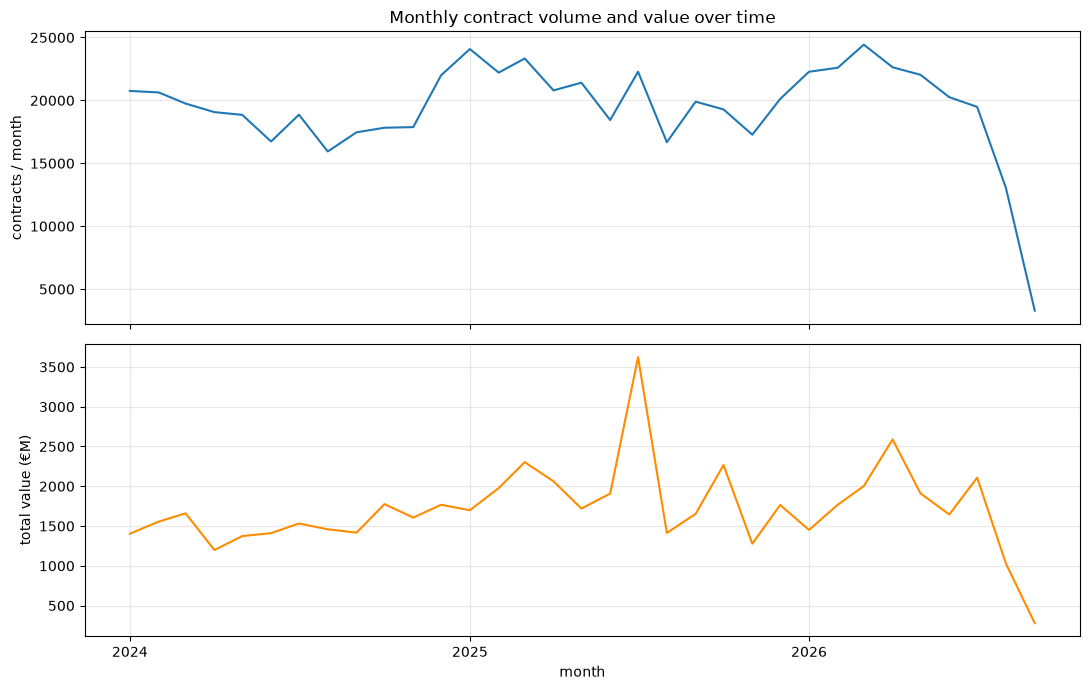

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Monthly contract volume and value over time")

axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


**Commentary:** contract *counts* and *value* do not always move together — a handful of very
large framework/infrastructure contracts can spike total value in a month with an otherwise
average count (consistent with the outlier tail seen in §3). Edge months at the very start/end
of the date range are typically partial (export cut-off), so should be treated with caution
when comparing to full calendar years. Any recurring monthly dips (e.g. around August, a common
low-activity month in Portuguese public administration) are worth a dedicated seasonal
decomposition in a follow-up pass rather than eyeballing here.

### Contract follow-up: a worked lifecycle example

We look for a contract where the closure date differs from the celebration date, or the
effective price differs from the contractual price — i.e. one that has actually been through
its full lifecycle in the data — and walk through what each field means.


In [20]:
lifecycle_example = (
    contracts
    .filter(
        pl.col("data_fecho").is_not_null()
        & (pl.col("data_fecho") != pl.col("data_celebracao"))
        & pl.col("preco_total_efetivo").is_not_null()
        & (pl.col("preco_total_efetivo") != pl.col("preco_contratual"))
    )
    .sort("preco_contratual", descending=True)
    .head(1)
)
lifecycle_example


idcontrato,adjudicante_nipc,adjudicante_name,adjudicatarios_nipc,adjudicatarios_name,objecto_contrato,preco_contratual,preco_total_efetivo,data_publicacao,data_celebracao,data_fecho,cpv,nuts,ano,tipo_contrato,tipo_procedimento,adjudicatario_pmes,prazo_execucao,adjudicatarios,adjudicatarios_nipc_correct,number_adjudicatarios,concorrentes,concorrentes_nipc,concorrentes_name,concorrentes_nipc_correct
i64,str,str,str,str,str,f64,f64,date,date,date,str,str,i64,str,str,str,i64,str,str,u32,str,str,str,str
10942305,"""512012032""","""EDA - Electricidade dos Açores…","""512033838""","""Bencom- Armazenamento e Comérc…","""Fornecimento de Fuelóleo às Ce…",4.9982e7,4.8524e7,2024-09-28,2024-09-28,2025-10-15,"""09135000-4 - Fuelóleos""","""PT200 - Região Autónoma dos Aç…",2024,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",null,365,"""512033838 - Bencom- Armazename…","""YES""",1,null,null,null,null


In [21]:
row = lifecycle_example.row(0, named=True)
print(f"idcontrato:        {row['idcontrato']}")
print(f"adjudicante:       {row['adjudicante_name']} ({row['adjudicante_nipc']})")
print(f"objecto:           {row['objecto_contrato']}")
print()
print(f"data_publicacao:   {row['data_publicacao']}   (announced to the market)")
print(f"data_celebracao:   {row['data_celebracao']}   (contract signed)")
print(f"data_fecho:        {row['data_fecho']}   (contract formally closed)")
print()
print(f"preco_contratual:     € {row['preco_contratual']:,.2f}  (agreed price at signature)")
print(f"preco_total_efetivo:  € {row['preco_total_efetivo']:,.2f}  (actual amount paid/executed by closure)")
delta = row["preco_total_efetivo"] - row["preco_contratual"]
print(f"delta:                € {delta:,.2f}  ({delta / row['preco_contratual']:+.1%} vs contractual)")


idcontrato:        10942305
adjudicante:       EDA - Electricidade dos Açores, S. A. (512012032)
objecto:           Fornecimento de Fuelóleo às Centrais Termoelétricas da EDA

data_publicacao:   2024-09-28   (announced to the market)
data_celebracao:   2024-09-28   (contract signed)
data_fecho:        2025-10-15   (contract formally closed)

preco_contratual:     € 49,981,673.47  (agreed price at signature)
preco_total_efetivo:  € 48,523,899.66  (actual amount paid/executed by closure)
delta:                € -1,457,773.81  (-2.9% vs contractual)


This illustrates why `SCHEMA.md`'s `keep="last"` dedup rule matters: `data_fecho` and
`preco_total_efetivo` are only known once BASE updates the row after execution, so an earlier
snapshot of this `idcontrato` would show both fields as null and `preco_contratual` as the only
price on record. The gap between `preco_contratual` and `preco_total_efetivo` reflects amendments,
extensions, or reductions made during execution — a field that would be lost entirely if the
notebook (or the DB load) kept the *first* seen version of a contract instead of the last.


## 6. Database / schema improvement suggestions

Grounded in what we observed in §3–§5, against the current `SCHEMA.md` design.

**Indexing**
- Already indexed per `SCHEMA.md`: `adjudicante_nipc`, `data_celebracao`, `cpv`, `ano`. These
  line up with the group-bys we actually ran above (by entity, by month, and — not shown but
  implied by §7 — by CPV).
- Additional candidates: a composite index on `(ano, tipo_procedimento)` or
  `(adjudicante_nipc, ano)` — Grafana filter combos in practice tend to stack a year range with
  either an entity or a procedure-type filter, and the top-entity aggregation in §4 groups by
  `adjudicante_nipc` first. A functional index on `cpv` prefix (e.g. `substring(cpv, 1, 2)`)
  would help category-level roll-ups without needing a full CPV hierarchy table for every query.
- The `data_celebracao::timestamp` IMMUTABLE-cast trick documented in `SCHEMA.md` (used by
  `v_contracts_enriched` / `006_timestamp_cast_indexes.sql`) is the right call — our monthly
  time series in §5 is exactly the query pattern (`$__timeFilter` range scan) that benefits from
  an expression index only being possible because the cast is immutable.

**Normalization**
- A CPV hierarchy table (division → group → class → category, from the 2/4/6/8-digit prefix
  structure) would let dashboards roll up categories without string-prefix filtering on `cpv`
  at query time — directly useful since `cpv` is high-cardinality (thousands of distinct codes)
  and low-level codes are too granular for exec-level charts.
- A NUTs hierarchy table (NUTS I/II/III → municipality) — `nuts` is currently a single
  free-text-ish field; geographic roll-ups (e.g. region-level spend) require string parsing
  today.

**Partitioning**
- If the table keeps growing yearly, partitioning `contracts` by `ano` (already a first-class,
  indexed column, and the field with the cleanest range semantics) would let old years be
  vacuumed/archived independently and would let the planner prune partitions for the very common
  year-filtered dashboard queries.

**Materialized views**
- The by-entity aggregation (§4: `n_contracts`, `total_value` per `adjudicante_nipc`) and the
  monthly time series (§5) are exactly the kind of aggregate a dashboard re-runs on every load.
  Both are cheap to materialize (`mv_entity_totals`, `mv_monthly_contracts`) and refresh on a
  schedule (e.g. nightly, matching the ingestion cadence) rather than recomputed per Grafana
  panel render.

**Data-quality constraints**
- `CHECK (preco_total_efetivo >= 0)` and `CHECK (preco_contratual >= 0)` — §3 found no negative
  values in this extract, but nothing currently prevents one from an amended row.
- `CHECK (data_fecho IS NULL OR data_fecho >= data_celebracao)` — worth adding; §3's sanity
  check for `data_celebracao < data_publicacao` suggests occasional date inconsistencies exist
  upstream and a symmetric check on closure vs celebration would catch the same class of issue.
- The FK cascade from `contract_adjudicatarios` to `contracts` (already present) is the right
  design given contracts are periodically re-ingested and superseded.


## 7. Other suggestions / limitations

- **CPV code enrichment**: joining `cpv` against the official EU CPV vocabulary (code → human
  description) would make category-level analysis and dashboards far more legible than raw
  8-digit codes.
- **Geocoding NUTs**: enriching `nuts` with lat/lon centroids or shapefiles would enable map
  visualizations of spend, which are currently not possible from the raw field alone.
- **Entity resolution beyond fuzzy name match**: §4's `token_sort_ratio` pass is a heuristic;
  a more robust approach would cross-reference NIPCs against Portugal's official taxpayer
  registry (or the RNPC) to confirm whether "near-duplicate" names actually share a legal
  identity (mergers, branch offices, renamed municipalities) rather than merging on name
  similarity alone.
- **Currency / inflation adjustment**: the multi-year time series in §5 compares nominal euros;
  a real-terms (CPI-deflated) series would be needed before drawing conclusions about growth in
  procurement *activity* vs simple price inflation.
- **Outlier-contract watchlist**: the top-10 highest-value contracts in §3 are worth a
  standing, monitored list (e.g. refreshed monthly) rather than a one-off query — useful both
  for anomaly detection (data-entry errors) and for genuine oversight of the largest public
  contracts.
- **Missing-data caveats**: this notebook works from a single xlsx snapshot
  (`contratos2025.xlsx`). Because BASE amends rows after signature (the reason for `keep="last"`
  dedup), any contract not yet updated by the export date will show stale/null `data_fecho` and
  `preco_total_efetivo` even though it may have since closed — all "closure" and "effective
  price" statistics above are therefore a lower bound as of the export date, not a final count.
- **Full bridge-table parse**: §2 parses `adjudicatarios` / `concorrentes` into `\n`-joined NIPC and
  name columns with a NIPC check, but does not explode them into the `contract_adjudicatarios`
  grain documented in `SCHEMA.md`; a follow-up notebook could do that (including `position`
  within the packed string) to analyze awardee concentration, competition levels, and
  multi-awardee contracts. `NO_NIF` awardees (NIPC `-`) cannot be joined to an entity table and
  would need their own handling.


In [22]:
contracts.select(pl.col("tipo_procedimento")).unique()

tipo_procedimento
str
"""Concurso de conceção simplific…"
"""Contratação excluída II"""
"""Consulta prévia ao abrigo do a…"
"""Ajuste Direto Regime Geral ao …"
"""Concurso público simplificado"""
"""Ajuste Direto Regime Geral"""
"""Setores especiais – isenção pa…"
"""Concurso público"""
"""Consulta Prévia"""
